In [ ]:
!pip -q install scqubits

In [ ]:
import numpy as np
import scqubits as scq
import matplotlib.pyplot as plt

qubit = scq.TunableTransmon(
    EJmax=50.0,       # Maximum Josephson energy, in GHz
    EC=0.25,          # Charging energy, in GHz
    d=0.05,           # Junction asymmetry parameter
    flux=0.0,         # External flux, in units of flux quantum
    ng=0.0,           # Offset charge
    ncut=20,          # Charge basis cutoff
    truncated_dim=6  # Number of low-energy states to retain
)

In [ ]:
H_charge = qubit.hamiltonian(energy_esys=False)

print("Hamiltonian shape:", H_charge.shape)
print(H_charge)

Hamiltonian shape: (41, 41)
[[400. -25.   0. ...   0.   0.   0.]
 [-25. 361. -25. ...   0.   0.   0.]
 [  0. -25. 324. ...   0.   0.   0.]
 ...
 [  0.   0.   0. ... 324. -25.   0.]
 [  0.   0.   0. ... -25. 361. -25.]
 [  0.   0.   0. ...   0. -25. 400.]]


In [ ]:
energies = qubit.eigenvals(evals_count=6)

print("Energy levels (GHz):")
print(energies)

# Transition frequencies relative to the ground state
frequencies = energies - energies[0]

print("\nTransitions from ground state (GHz):")
print(frequencies)

Energy levels (GHz):
[-45.06331229 -35.3200142  -25.84262677 -16.64359749  -7.737526
   0.85814084]

Transitions from ground state (GHz):
[ 0.          9.74329809 19.22068552 28.4197148  37.32578629 45.92145313]


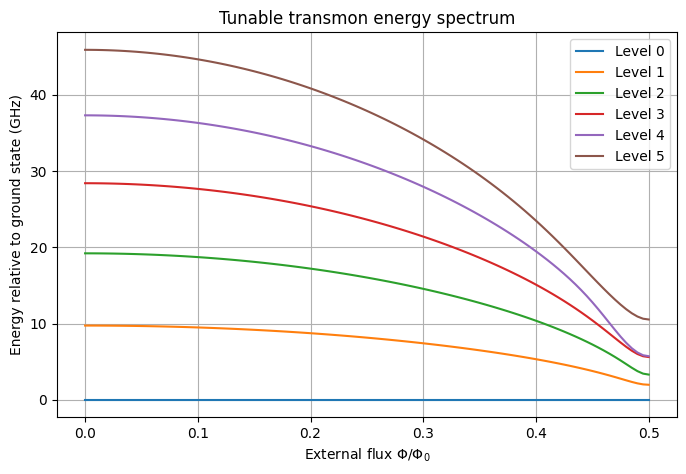

In [ ]:
flux_values = np.linspace(0, 0.5, 101)

spectrum = qubit.get_spectrum_vs_paramvals(
    param_name="flux",
    param_vals=flux_values,
    evals_count=6
)

plt.figure(figsize=(8, 5))

for i in range(6):
    plt.plot(
        flux_values,
        spectrum.energy_table[:, i] - spectrum.energy_table[:, 0],
        label=f"Level {i}"
    )

plt.xlabel(r"External flux $\Phi/\Phi_0$")
plt.ylabel("Energy relative to ground state (GHz)")
plt.title("Tunable transmon energy spectrum")
plt.grid(True)
plt.legend()
plt.show()

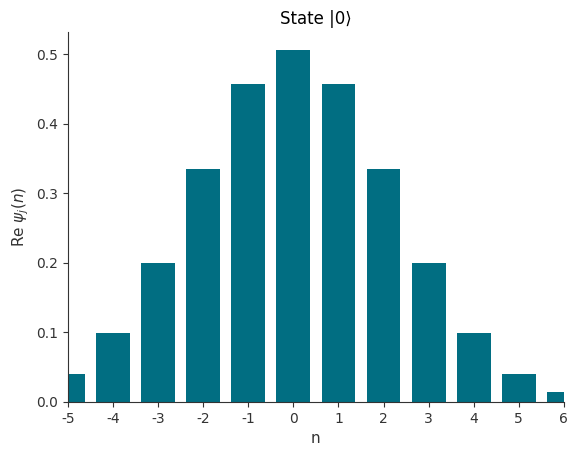

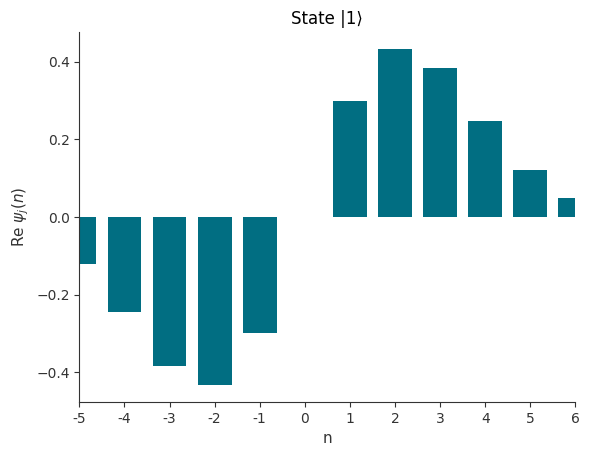

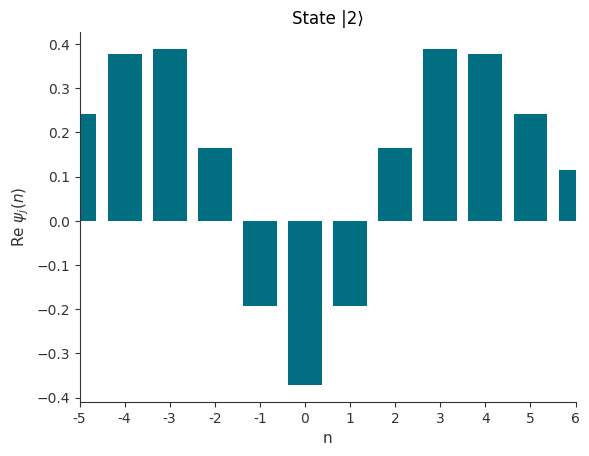

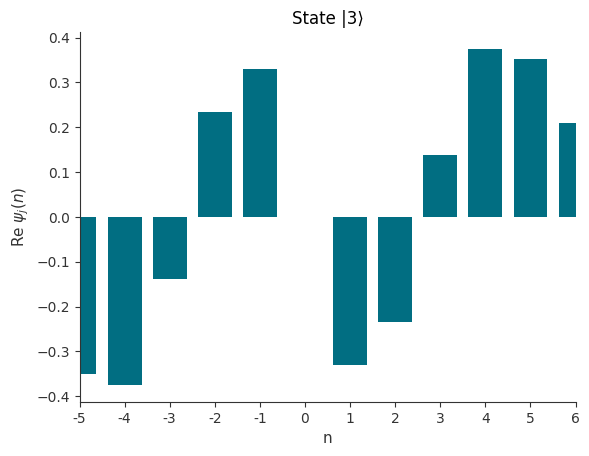

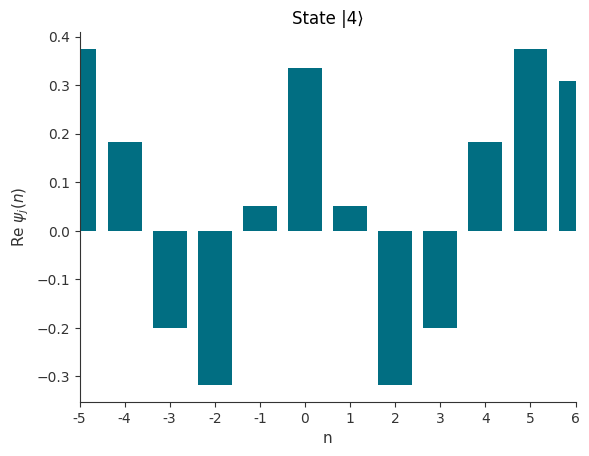

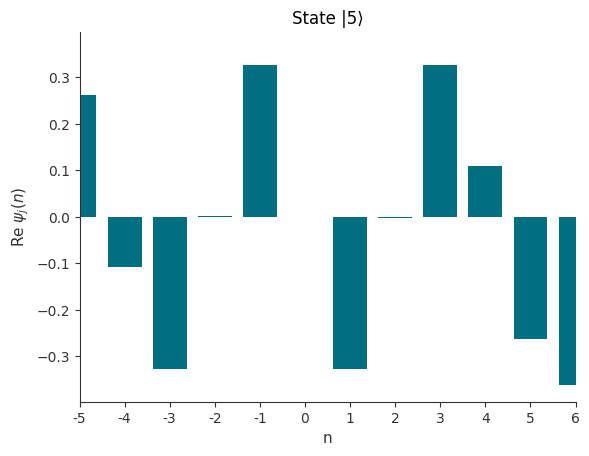

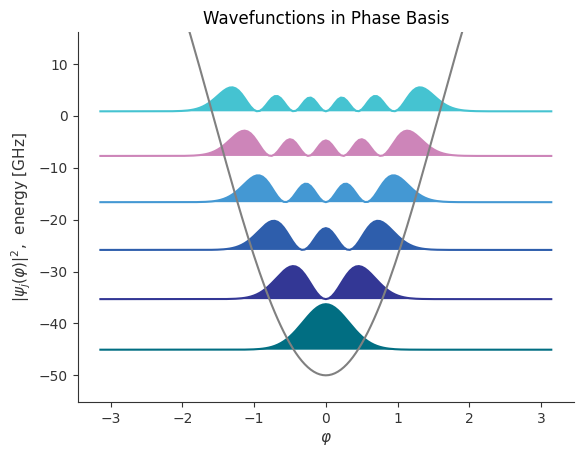

In [ ]:
# Calculate eigensystem
esys = qubit.eigensys(evals_count=6)

# Plot wavefunctions in charge basis
for state in [0, 1, 2, 3, 4, 5 ]:
    fig, ax = qubit.plot_n_wavefunction(esys=esys, which=state)
    ax.set_title(f"State |{state}⟩")

plt.show()

# Plot wavefunctions in phase basis
fig, ax = qubit.plot_phi_wavefunction(esys=esys, which=[0, 1, 2, 3, 4, 5])

ax.set_title("Wavefunctions in Phase Basis")
plt.show()

In [ ]:
import inspect

print("Charge basis:")
print(inspect.signature(qubit.plot_n_wavefunction))

print("\nPhase basis:")
print(inspect.signature(qubit.plot_phi_wavefunction))

Charge basis:
(esys: Tuple[numpy.ndarray, numpy.ndarray] = None, mode: str = 'real', which: int = 0, nrange: Tuple[int, int] = None, **kwargs) -> Tuple[matplotlib.figure.Figure, matplotlib.axes._axes.Axes]

Phase basis:
(esys: Tuple[numpy.ndarray, numpy.ndarray] = None, which: int = 0, phi_grid: scqubits.core.discretization.Grid1d = None, mode: str = 'abs_sqr', scaling: float = None, **kwargs) -> Tuple[matplotlib.figure.Figure, matplotlib.axes._axes.Axes]


In [ ]:
# 1. Charge operator in the raw Charge Basis (41x41 diagonal matrix)
n_charge = qubit.n_operator(energy_esys=False)
print("Charge basis n_operator shape:", n_charge.shape)
print("Diagonal charge values (n):")
print(np.diag(n_charge))
print(n_charge)

# 2. Charge operator transformed into the Energy Eigenbasis (6x6 matrix using truncated_dim)
n_energy = qubit.n_operator(energy_esys=esys)
print("\nEnergy eigenbasis n_operator shape:", n_energy.shape)
print("Matrix elements n_ij between lowest 6 eigenstates:")
print(np.round(n_energy, 4))

Charge basis n_operator shape: (41, 41)
Diagonal charge values (n):
[-20 -19 -18 -17 -16 -15 -14 -13 -12 -11 -10  -9  -8  -7  -6  -5  -4  -3
  -2  -1   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15
  16  17  18  19  20]
[[-20   0   0 ...   0   0   0]
 [  0 -19   0 ...   0   0   0]
 [  0   0 -18 ...   0   0   0]
 ...
 [  0   0   0 ...  18   0   0]
 [  0   0   0 ...   0  19   0]
 [  0   0   0 ...   0   0  20]]

Energy eigenbasis n_operator shape: (6, 6)
Matrix elements n_ij between lowest 6 eigenstates:
[[-0.0000e+00  1.5606e+00 -0.0000e+00  2.5900e-02 -0.0000e+00 -9.0000e-04]
 [ 1.5606e+00 -0.0000e+00  2.1766e+00  0.0000e+00  5.3700e-02  0.0000e+00]
 [-0.0000e+00  2.1766e+00  0.0000e+00  2.6259e+00  0.0000e+00 -8.8400e-02]
 [ 2.5900e-02  0.0000e+00  2.6259e+00  0.0000e+00  2.9827e+00  0.0000e+00]
 [-0.0000e+00  5.3700e-02  0.0000e+00  2.9827e+00 -0.0000e+00 -3.2749e+00]
 [-9.0000e-04  0.0000e+00 -8.8400e-02  0.0000e+00 -3.2749e+00  0.0000e+00]]


In [ ]:
# 1. Charge operator in the raw Charge Basis (41x41 diagonal matrix)
n_charge_exp_phi = qubit.exp_i_phi_operator(energy_esys=False)
print("Charge basis n_operator shape:", n_charge_exp_phi.shape)
print("Diagonal charge values (n):")
print(np.diag(n_charge_exp_phi))
print(n_charge_exp_phi)

# 2. Charge operator transformed into the Energy Eigenbasis (6x6 matrix using truncated_dim)
n_energy_exp_phi = qubit.exp_i_phi_operator(energy_esys=esys)
print("\nEnergy eigenbasis n_operator shape:", n_energy_exp_phi.shape)
print("Matrix elements n_ij between lowest 6 eigenstates:")
print(np.round(n_energy_exp_phi, 4))

Charge basis n_operator shape: (41, 41)
Diagonal charge values (n):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[[0. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 1. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]]

Energy eigenbasis n_operator shape: (6, 6)
Matrix elements n_ij between lowest 6 eigenstates:
[[ 9.500e-01 -3.041e-01  6.930e-02 -1.470e-02  3.300e-03  8.000e-04]
 [ 3.041e-01  8.499e-01 -4.126e-01  1.183e-01 -2.960e-02 -7.600e-03]
 [ 6.930e-02  4.126e-01  7.497e-01 -4.831e-01  1.648e-01  4.720e-02]
 [ 1.470e-02  1.183e-01  4.831e-01  6.491e-01 -5.313e-01 -2.092e-01]
 [ 3.300e-03  2.960e-02  1.648e-01  5.313e-01  5.479e-01  5.630e-01]
 [-8.000e-04 -7.600e-03 -4.720e-02 -2.092e-01 -5.630e-01  4.459e-01]]


In [ ]:
n_charge_cos_phi = qubit.cos_phi_operator(energy_esys=False)
print("Charge basis n_operator shape:", n_charge_cos_phi.shape)
print("Diagonal charge values (n):")
print(np.diag(n_charge_cos_phi))
print(n_charge_cos_phi)

n_energy_cos_phi = qubit.cos_phi_operator(energy_esys=esys)
print("\nEnergy eigenbasis n_operator shape:", n_energy_cos_phi.shape)
print("Matrix elements n_ij between lowest 6 eigenstates:")
print(np.round(n_energy_cos_phi, 4))

Charge basis n_operator shape: (41, 41)
Diagonal charge values (n):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[[0.  0.5 0.  ... 0.  0.  0. ]
 [0.5 0.  0.5 ... 0.  0.  0. ]
 [0.  0.5 0.  ... 0.  0.  0. ]
 ...
 [0.  0.  0.  ... 0.  0.5 0. ]
 [0.  0.  0.  ... 0.5 0.  0.5]
 [0.  0.  0.  ... 0.  0.5 0. ]]

Energy eigenbasis n_operator shape: (6, 6)
Matrix elements n_ij between lowest 6 eigenstates:
[[ 0.95   -0.      0.0693  0.      0.0033  0.    ]
 [-0.      0.8499  0.      0.1183  0.     -0.0076]
 [ 0.0693  0.      0.7497  0.      0.1648 -0.    ]
 [-0.      0.1183  0.      0.6491 -0.     -0.2092]
 [ 0.0033 -0.      0.1648  0.      0.5479  0.    ]
 [-0.     -0.0076 -0.     -0.2092  0.      0.4459]]


The 6x6 Transition Table:
[[0.000e+00 1.561e+00 0.000e+00 2.600e-02 0.000e+00 1.000e-03]
 [1.561e+00 0.000e+00 2.177e+00 0.000e+00 5.400e-02 0.000e+00]
 [0.000e+00 2.177e+00 0.000e+00 2.626e+00 0.000e+00 8.800e-02]
 [2.600e-02 0.000e+00 2.626e+00 0.000e+00 2.983e+00 0.000e+00]
 [0.000e+00 5.400e-02 0.000e+00 2.983e+00 0.000e+00 3.275e+00]
 [1.000e-03 0.000e+00 8.800e-02 0.000e+00 3.275e+00 0.000e+00]]


(<Figure size 1000x500 with 3 Axes>, (<Axes3D: >, <Axes: >))

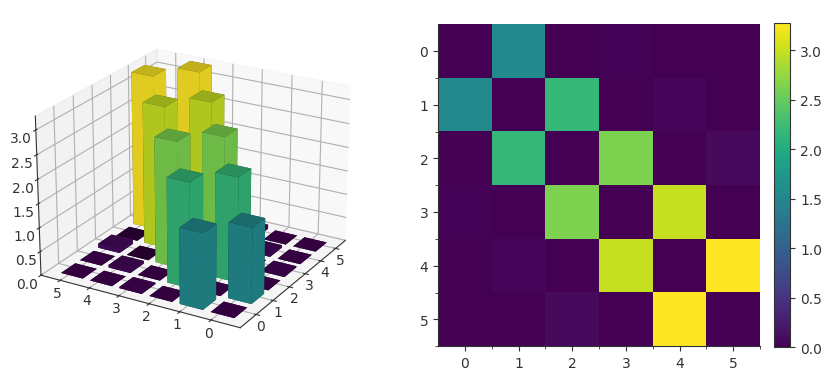

In [ ]:
# 1. Print the actual 6x6 grid of numbers for the charge operator ('n')
print("The 6x6 Transition Table:")
table = qubit.matrixelement_table('n_operator', evals_count=6)
print(np.round(np.abs(table), 3))

# 2. Draw the 3D "Lego" plot of these exact same numbers
qubit.plot_matrixelements('n_operator', evals_count=6, show3d=True)

Calculating 50 different transition tables in the background...
Done! Now drawing the graph...


(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='$\\Phi_{ext}/\\Phi_0$', ylabel='matrix element'>)

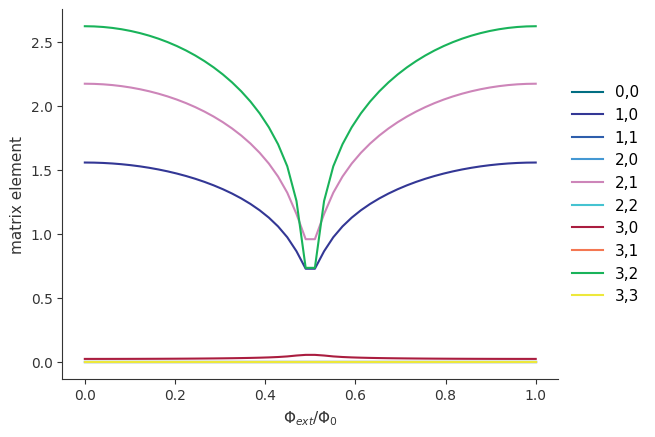

In [ ]:
# 1. Set up the dial settings (turning magnetic flux from 0.0 to 1.0 in 50 small clicks)
flux_dial_settings = np.linspace(0.0, 1.0, 50)

print("Calculating 50 different transition tables in the background...")
# 2. Run the calculator to get all the data
jump_data = qubit.get_matelements_vs_paramvals(
    operator='n_operator',
    param_name='flux',
    param_vals=flux_dial_settings,
    evals_count=6
)
print("Done! Now drawing the graph...")

# 3. Draw the line graph showing how the jumps change as the dial turns
qubit.plot_matelem_vs_paramvals(
    operator='n_operator',
    param_name='flux',
    param_vals=flux_dial_settings,
    select_elems = 4,
    mode='abs'
)

See documentation for details.
This warning can be disabled by executing:
scqubits.settings.T1_DEFAULT_WARNING=False

 /usr/local/lib/python3.13/dist-packages/scqubits/core/noise.py: 1213

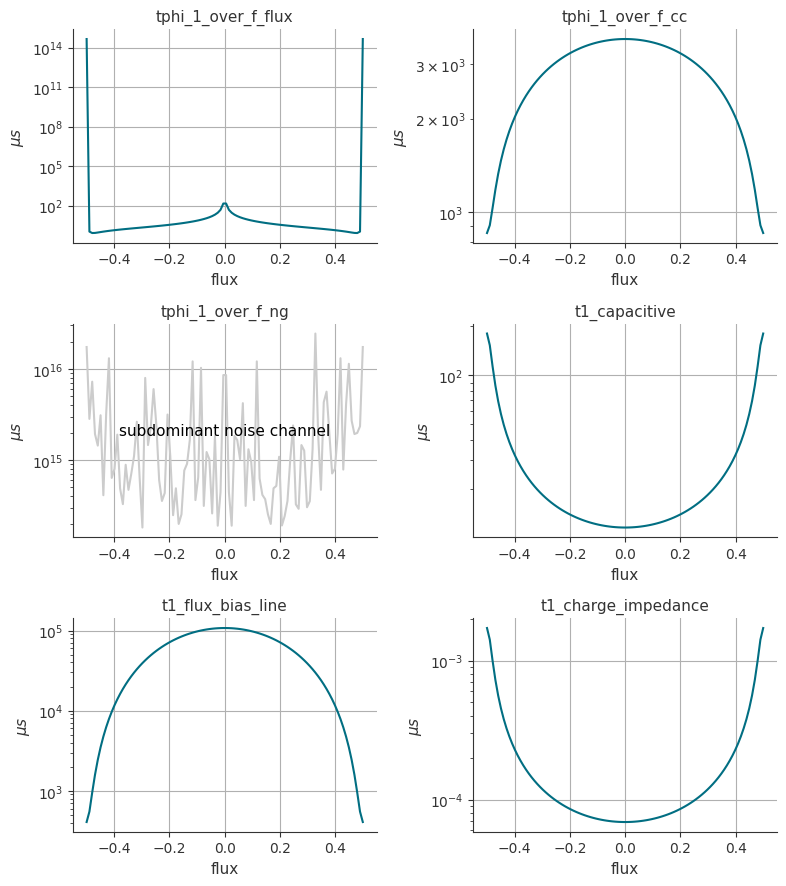

In [ ]:
qubit.plot_coherence_vs_paramvals(param_name='flux',
                                  param_vals=np.linspace(-0.5, 0.5, 100),
                                  scale=1e-3,
                                  ylabel=r"$\mu s$");

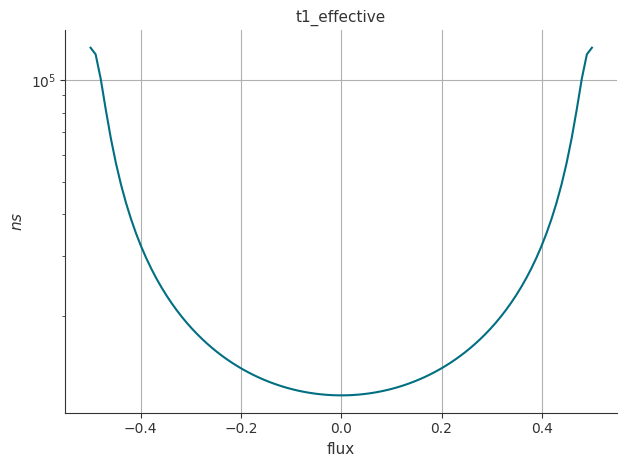

In [ ]:
qubit.plot_t1_effective_vs_paramvals(param_name='flux',
                                     param_vals=np.linspace(-0.5, 0.5, 100),
                                    );

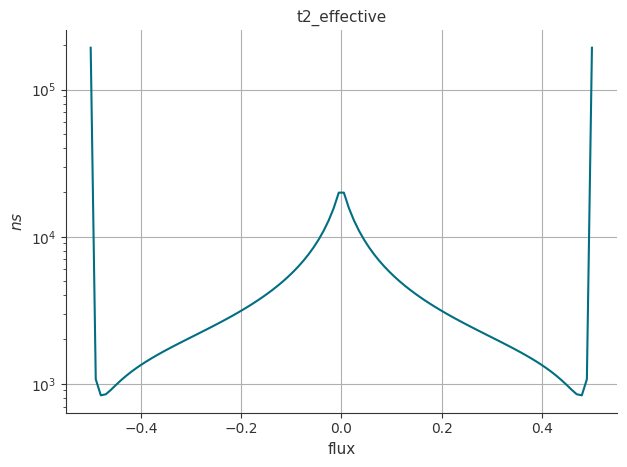

In [ ]:
qubit.plot_t2_effective_vs_paramvals(param_name='flux',
                                     param_vals=np.linspace(-0.5, 0.5, 100),
                                    );

In [ ]:
def ohmic_noise(omega,T):
  kappa = 0.0001
  return kappa * np.abs(omega)

# Get the actual matrix operator representing the charge operator
noise_op_matrix = qubit.n_operator()

t1_leak_time = qubit.t1(
    i = 1,
    j = 0,
    noise_op=noise_op_matrix,
    spectral_density=ohmic_noise,
    T=0.015,
)
print("The transition time from |1> to |0> is ",t1_leak_time)


The transition time from |1> to |0> is  33.53351705934919


In [ ]:
# Temporarily set truncated_dim to 41 to allow the full 41x41 energy representation
qubit.truncated_dim = 41

# Calculate the true 41x41 charge operator in the energy eigenbasis
n_energy_full_41 = qubit.n_operator(energy_esys=esys_full)

# Reset the truncated dimension back to 6 to keep your default setup intact
qubit.truncated_dim = 6

print("Full Energy Eigenbasis Charge Operator Shape:", n_energy_full_41.shape)
print("\nShowing a rounded 10x10 sub-block of the 41x41 matrix (representing the first 10 energy states):\n")
print(np.round(n_energy_full_41[:10, :10], 4))

Full Energy Eigenbasis Charge Operator Shape: (41, 41)

Showing a rounded 10x10 sub-block of the 41x41 matrix (representing the first 10 energy states):

[[ 0.0000e+00  1.5606e+00  0.0000e+00  2.5900e-02 -0.0000e+00 -9.0000e-04
  -0.0000e+00  0.0000e+00 -0.0000e+00  0.0000e+00]
 [ 1.5606e+00  0.0000e+00  2.1766e+00 -0.0000e+00  5.3700e-02  0.0000e+00
   2.3000e-03  0.0000e+00  1.0000e-04 -0.0000e+00]
 [ 0.0000e+00  2.1766e+00 -0.0000e+00  2.6259e+00  0.0000e+00 -8.8400e-02
  -0.0000e+00  4.7000e-03  0.0000e+00  4.0000e-04]
 [ 2.5900e-02 -0.0000e+00  2.6259e+00  0.0000e+00  2.9827e+00  0.0000e+00
   1.3060e-01 -0.0000e+00  8.6000e-03  0.0000e+00]
 [-0.0000e+00  5.3700e-02  0.0000e+00  2.9827e+00  0.0000e+00 -3.2749e+00
   0.0000e+00  1.8140e-01 -0.0000e+00  1.4500e-02]
 [-9.0000e-04  0.0000e+00 -8.8400e-02  0.0000e+00 -3.2749e+00 -0.0000e+00
  -3.5155e+00  0.0000e+00 -2.4220e-01  0.0000e+00]
 [ 0.0000e+00  2.3000e-03 -0.0000e+00  1.3060e-01  0.0000e+00 -3.5155e+00
   0.0000e+00  3.7106e

In [ ]:
# T1 leak time due to dirty capacitor metal
t1_leak_time = qubit.t1_capacitive(
    i=1,
    j=0,
    Q_cap=1000000,    # A solid, high-quality capacitor (1 million)
    T=0.015
)

print(f"Due to the capacitor, the qubit will die in {t1_leak_time} time units.")
print(t1_leak_time)

Due to the capacitor, the qubit will die in 16336.3526289051 time units.
16336.3526289051


In [ ]:
# Calculate how fast the energy leaks out through the physical cables
t1_cable_leak = qubit.t1_charge_impedance(
    i=1,
    j=0,
    Z=50,       # 50-Ohm standard lab cables
    T=0.015     # 15 mK temperature
)

print(f"Due to the 50-Ohm cables, the qubit dies in {t1_cable_leak} units of time.")

Due to the 50-Ohm cables, the qubit dies in 0.06888179935558705 units of time.
